# 11 · Cookie Cats: загрузка и A/A-проверка

Шаг 11–12 плана Part 2. Данные — реальный A/B-тест Cookie Cats: перенос первого
gate с уровня 30 на 40. Проверяю качество, SRM (sample ratio mismatch) и A/A
placebo до любого сравнения retention. Данные лежат вне git; в репозиторий едут
только агрегаты и графики.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_AB, PROCESSED, RANDOM_SEED, figures
from data import load_raw, load_clean, CLEAN_PARQUET
from experiment import srm_test, two_proportion_ztest, aa_placebo, baseline_table, wilson_ci
FIG = figures(CASE_AB); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
raw = load_raw()
df = load_clean()
print('raw:', raw.shape, '· clean:', df.shape)
print(df.dtypes)
df.head()

raw: (90189, 5) · clean: (90189, 5)
userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## Качество данных

Проверяю уникальность `userid`, пропуски, метки версий, отрицательные раунды и
выбросы. Строки не удаляю: выброс по `sum_gamerounds` — часть распределения,
а не ошибка ввода.

In [2]:
print('duplicates userid:', int(df.userid.duplicated().sum()))
print('missing:', df.isna().sum().to_dict())
print(df.version.value_counts().to_string())
print(df.sum_gamerounds.describe().round(1).to_string())
print('нулевых раундов:', int((df.sum_gamerounds == 0).sum()),
      '· максимум:', int(df.sum_gamerounds.max()))
assert df.userid.is_unique and not df.isna().any().any()
assert set(df.version.unique()) == {'gate_30', 'gate_40'}


duplicates userid: 0
missing: {'userid': 0, 'version': 0, 'sum_gamerounds': 0, 'retention_1': 0, 'retention_7': 0}
version
gate_40    45489
gate_30    44700
count    90189.0
mean        51.9
std        195.1
min          0.0
25%          5.0
50%         16.0
75%         51.0
max      49854.0
нулевых раундов: 3994 · максимум: 49854


## SRM: размеры групп

SRM проверяет, что сплитование не сломано. Порог жёсткой остановки — p < 0.001;
p < 0.01 считаю предупреждением, а не приговором: при 90 тыс. пользователей
небольшой дисбаланс даёт заметный хи-квадрат.

In [3]:
counts = df.version.value_counts()
srm = srm_test(counts)
print('наблюдаемо:', dict(zip(srm['labels'], srm['observed'])))
print('ожидаемо:  ', [round(x, 1) for x in srm['expected']])
print(f"chi2 = {srm['chi2']:.3f} · p = {srm['p_value']:.4f} · max imbalance = {srm['max_imbalance_pp']:.3f} п.п.")
print('жёсткая остановка p<0.001:', srm['p_value'] < 0.001)
print('предупреждение p<0.01:  ', srm['p_value'] < 0.01)
assert srm['n'] == len(df)


наблюдаемо: {'gate_40': 45489.0, 'gate_30': 44700.0}
ожидаемо:   [45094.5, 45094.5]
chi2 = 6.902 · p = 0.0086 · max imbalance = 0.437 п.п.
жёсткая остановка p<0.001: False
предупреждение p<0.01:   True


## A/A placebo

Случайно делю пул 50/50 1 000 раз и считаю долю p < 0.05. Если процедура
корректна, доля близка к 5 %. Это проверка пайплайна, а не реального сплита:
в данных нет отдельной A/A-группы.

In [4]:
aa_rows, aa_pvals = [], {}
for metric in ['retention_1', 'retention_7']:
    res = aa_placebo(df, metric, RNG, n_iter=1000)
    aa_pvals[metric] = res['p_values']
    aa_rows.append({'metric': metric, 'n_iter': res['n_iter'],
                    'false_positive_rate': res['false_positive_rate']})
aa_table = pd.DataFrame(aa_rows)
aa_table.round(4)


,metric,n_iter,false_positive_rate
0,retention_1,1000,0.054
1,retention_7,1000,0.060


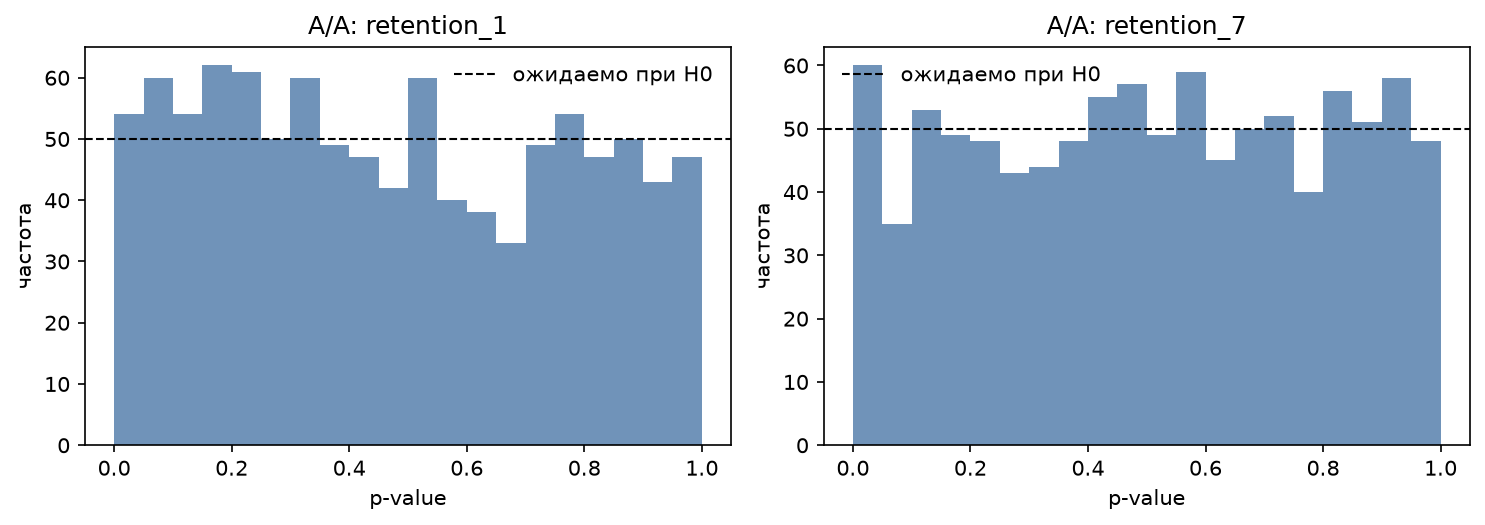

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=150)
for ax, metric in zip(axes, ['retention_1', 'retention_7']):
    ax.hist(aa_pvals[metric], bins=20, range=(0, 1), color='#4C78A8', alpha=.8)
    ax.axhline(len(aa_pvals[metric]) / 20, color='black', ls='--', lw=1, label='ожидаемо при H0')
    ax.set(xlabel='p-value', ylabel='частота', title=f'A/A: {metric}')
    ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / '03-aa-pvalues.png'); plt.show()


## Описательное сравнение групп

Это ещё не финальная оценка эффекта: SRM и множественные метрики требуют
осторожности. Смотрю направление и интервалы, чтобы понять, куда двигаться.

In [6]:
base = baseline_table(df)
base.round(4)


,metric,n_gate_30,n_gate_40,gate_30,gate_40,p_a,p_b,diff,ci_low,ci_high,z,p_value,relative_lift
0,retention_1,44700,45489,0.4482,0.4423,0.4482,0.4423,-0.0059,-0.0124,0.0006,-1.7841,0.0744,-0.0132
1,retention_7,44700,45489,0.1902,0.1820,0.1902,0.1820,-0.0082,-0.0133,-0.0031,-3.1644,0.0016,-0.0431


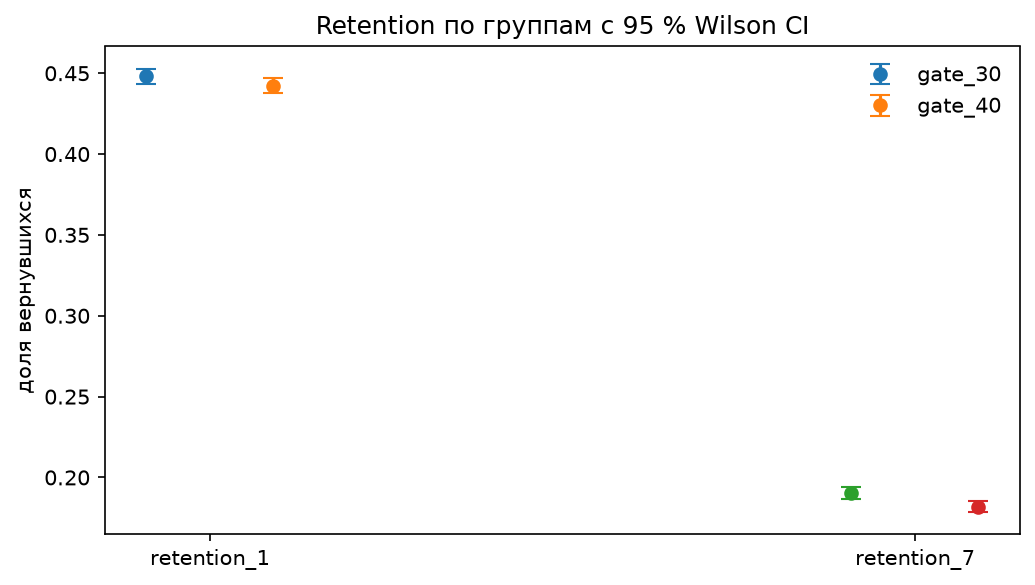

In [7]:
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
for i, metric in enumerate(['retention_1', 'retention_7']):
    for j, version in enumerate(['gate_30', 'gate_40']):
        sub = df[df.version == version]
        p = sub[metric].mean()
        lo, hi = wilson_ci(sub[metric].sum(), len(sub))
        ax.errorbar(i + (j - 0.5) * 0.18, p, yerr=[[p - lo], [hi - p]],
                    fmt='o', capsize=5, label=version if i == 0 else None)
ax.set_xticks([0, 1], ['retention_1', 'retention_7'])
ax.set(ylabel='доля вернувшихся', title='Retention по группам с 95 % Wilson CI')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / '01-retention-by-group.png'); plt.show()


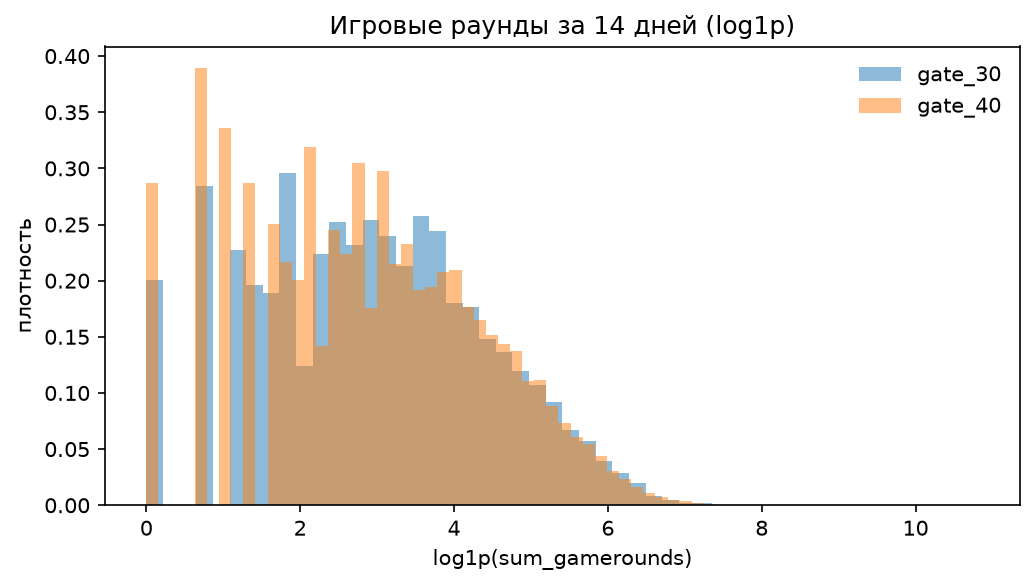

In [8]:
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
for version in ['gate_30', 'gate_40']:
    ax.hist(np.log1p(df.loc[df.version == version, 'sum_gamerounds']),
            bins=50, alpha=.5, density=True, label=version)
ax.set(xlabel='log1p(sum_gamerounds)', ylabel='плотность',
       title='Игровые раунды за 14 дней (log1p)')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / '02-gamerounds-distribution.png'); plt.show()


## Сохранение результата проверки

In [9]:
summary = {
    'n': int(len(df)),
    'groups': {k: int(v) for k, v in df.version.value_counts().items()},
    'srm': {k: v for k, v in srm.items() if k not in ('observed', 'expected')},
    'aa': aa_table.to_dict(orient='records'),
    'baseline': base.to_dict(orient='records'),
}
(PROCESSED / 'cookie_cats_aa_check.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('saved', PROCESSED / 'cookie_cats_aa_check.json')


saved E:\Projects\Product_Analytics_Portfolio\data\processed\cookie_cats_aa_check.json


## Что видно

- SRM: χ² = 6.90, p = 0.0086, дисбаланс 0.44 п.п. Это предупреждение, а не
  жёсткая остановка (p > 0.001), но финальный вывод обязан проверить
  чувствительность к SRM.
- A/A placebo: доля ложных срабатываний около 5 % — процедура не раздувает
  ошибку первого рода.
- `retention_1`: 44.82 % против 44.23 %, разница −0.59 п.п., p = 0.074.
- `retention_7`: 19.02 % против 18.20 %, разница −0.82 п.п., p = 0.0016.
  Направление отрицательное: gate на 40 хуже для 7-дневного возврата.
- Следующий шаг: финальная оценка с поправкой на SRM-чувствительность,
  guardrail-метрики и решение о раскатке. Числа пока описательные.